# 10. Sequence Models for Volatility Prediction

## Introduction and Scope

In Stage 0, we investigated volatility prediction using conventional statistical features, topological data analysis (TDA), and several machine-learning models: Logistic Regression, Random Forest, XGBoost, and a feedforward neural network. Random Forest achieved the highest test F1 score, although the neural network performed comparably.

These models treated each observation as a fixed-dimensional feature vector. However, financial data are inherently sequential, and their temporal dependencies may contain information that is not adequately captured by engineered features alone.

The objective of this notebook is to investigate **whether explicitly modeling temporal dependencies improves volatility prediction**.

We will proceed in three stages:

1. **Time-series exploration.** Visualize SPY returns and volatility, examine temporal dependence, and investigate statistical properties relevant to sequence modeling, including stationarity and autocorrelation.

2. **Classical time-series baselines.** Introduce and experiment with the autoregressive (AR), moving-average (MA), and autoregressive moving-average (ARMA) model families. These models will provide interpretable baselines for understanding linear temporal dependence. We will also consider whether their assumptions are appropriate for financial returns and volatility.

3. **Recurrent neural networks.** Construct sequential input data and train recurrent neural networks (RNNs) to investigate whether nonlinear temporal dependencies improve prediction. We will begin with a simple RNN and consider more advanced recurrent architectures if justified by the results.

### Prediction Task and Evaluation

We retain the Stage-0 prediction task: predicting whether future five-day realized volatility exceeds current 20-day volatility by a specified relative amount.

The binary target is

$$
y_t =
\begin{cases}
1, & \displaystyle \log\left(\frac{RV_{t,t+5}}{Vol_{t,20}}\right)>0.2,\\[6pt]
0, & \text{otherwise},
\end{cases}
$$

where $RV_{t,t+5}$ is the realized volatility over the next five trading days and $Vol_{t,20}$ is the backward-looking 20-day volatility estimate.

We will retain the chronological training, validation, and test periods established in Stage 0. All preprocessing and sequence construction must respect temporal ordering and prevent information leakage.

Since classical ARMA models naturally forecast continuous time-series values rather than binary labels, their forecasts will require an appropriate transformation or decision rule before comparison with the classification models. We will distinguish the quality of the underlying time-series forecasts from their usefulness for the binary prediction task.

The final objective is to compare sequence-based approaches with the Stage-0 baselines using the same test observations and evaluation metrics, wherever possible.

## 1. Project Setup and Imports

We begin with the cleaned daily SPY dataset produced during Stage 0. Rather than using the previously engineered feature vectors, we will construct time-series representations directly from the historical price data.

This allows us to investigate temporal dependencies using classical time-series models and recurrent neural networks.

We will use NumPy and pandas for numerical operations and data manipulation, Matplotlib for visualization, and statsmodels for classical time-series analysis. PyTorch will be used for recurrent neural networks.

### 1.1: Import libraries

In [1]:
# Numerical computing
import numpy as np

# Data manipulation
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Project paths
from pathlib import Path

# Classical time-series analysis
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 1.2: Set project paths

In [2]:
# Locate the repository root.
PROJECT_ROOT = Path.cwd().parent

# Locate the cleaned data.
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Locate model artifacts.
MODELS_DIR = PROJECT_ROOT / "models"

# Locate generated figures.
FIGURES_DIR = PROJECT_ROOT / "figures"

# Create output directories if needed.
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

### 1.3: Load the cleaned SPY dataset

In [3]:
# Load the cleaned daily SPY data.
spy_data = pd.read_csv(
    PROCESSED_DATA_DIR / "spy_daily_clean.csv",
    index_col=0,
    parse_dates=True,
)

# Inspect the first observations.
spy_data.head()

,Close,High,Low,Open,Volume
2010-01-04,84.578491,84.623268,83.220220,83.862041,118944600
2010-01-05,84.802376,84.839693,84.220261,84.526247,111579900
2010-01-06,84.862091,85.071055,84.653127,84.720292,116074400
2010-01-07,85.220306,85.324788,84.466539,84.705356,131091100
2010-01-08,85.503906,85.541224,84.824774,84.996420,126402800


### 1.4: Construct daily log returns

In [4]:
# Compute daily log returns.
spy_data["log_return"] = np.log(
    spy_data["Close"] / spy_data["Close"].shift(1)
)

# Inspect the resulting time series.
spy_data[["Close", "log_return"]].head()

,Close,log_return
2010-01-04,84.578491,NaN
2010-01-05,84.802376,0.002644
2010-01-06,84.862091,0.000704
2010-01-07,85.220306,0.004212
2010-01-08,85.503906,0.003322


## 2. Exploratory Analysis of the Time Series

Before constructing statistical or neural sequence models, we investigate the temporal structure of SPY's historical price data.

Our initial exploration focuses on three time series:

1. **Adjusted closing prices:** The historical evolution of SPY's price, accounting for corporate actions.
2. **Daily log returns:** Relative changes in price, expressed on a logarithmic scale.
3. **Historical volatility:** The magnitude of recent return fluctuations, estimated using a rolling window.

These quantities exhibit different statistical properties. In particular, financial returns often display relatively weak linear autocorrelation, whereas their magnitudes and squared values can exhibit persistent temporal dependence. This phenomenon is associated with **volatility clustering**.

Our objective is to identify which temporal structures may be captured by classical autoregressive models and which might motivate nonlinear sequence models.

### 2.1: Visualizing SPY prices and returns

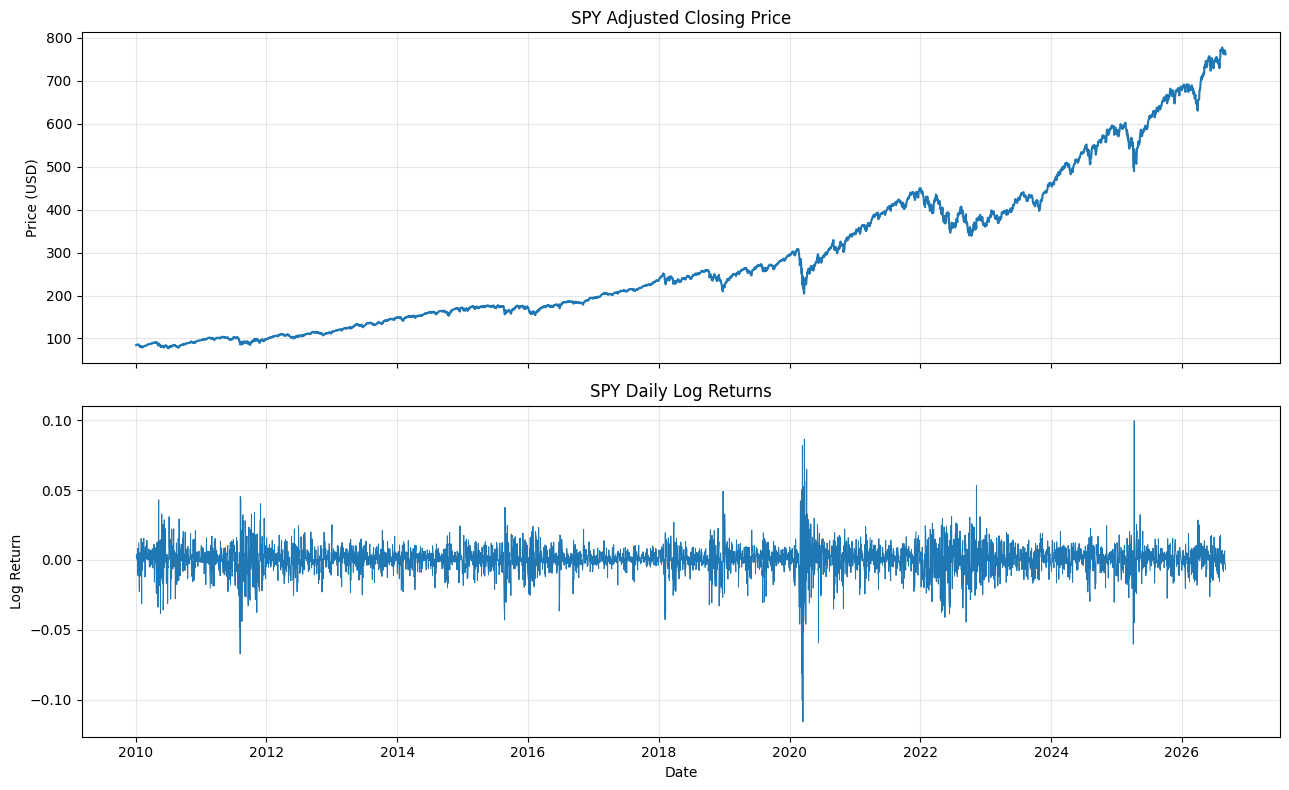

In [5]:
# Extract the adjusted closing-price series.
prices = spy_data["Close"]

# Extract the daily log-return series, excluding missing values.
returns = spy_data["log_return"].dropna()

# Create two vertically arranged plots.
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Plot adjusted closing prices.
axes[0].plot(prices.index, prices.values)

# Label the first plot.
axes[0].set_title("SPY Adjusted Closing Price")
axes[0].set_ylabel("Price (USD)")
axes[0].grid(alpha=0.3)

# Plot daily log returns.
axes[1].plot(returns.index, returns.values, linewidth=0.7)

# Label the second plot.
axes[1].set_title("SPY Daily Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].grid(alpha=0.3)

# Adjust spacing and display the plots.
plt.tight_layout()
plt.show()

### 2.2: Visualize historical volatility

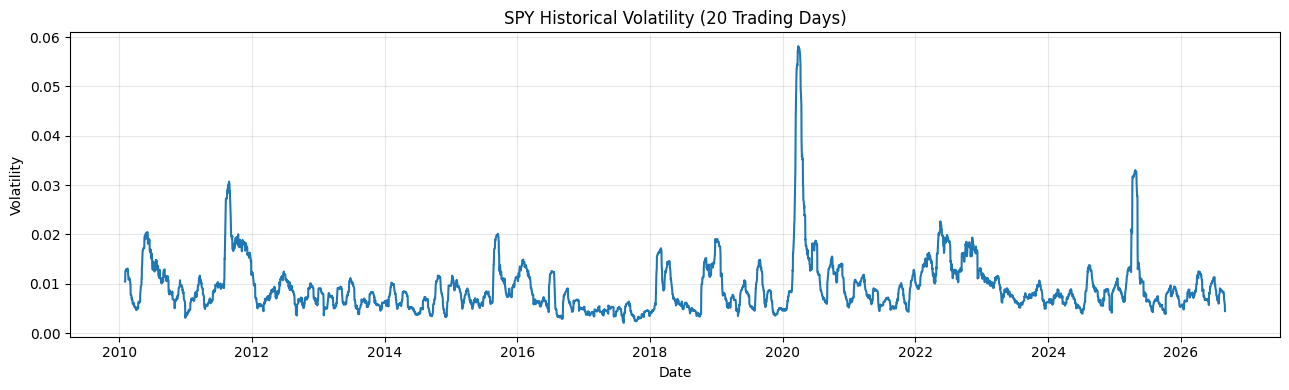

In [6]:
# Calculate backward-looking 20-day realized volatility:
volatility_20 = np.sqrt(
    returns.pow(2).rolling(window=20).mean()
)

# Create the volatility plot:
plt.figure(figsize=(13, 4))

# Plot the volatility series:
plt.plot(volatility_20.index, volatility_20.values)

# Add labels and formatting:
plt.title("SPY Historical Volatility (20 Trading Days)")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.grid(alpha=0.3)

# Display the plot:
plt.tight_layout()
plt.show()

### Observations

The three time series exhibit distinct statistical characteristics.

**Adjusted closing prices.** SPY prices display a pronounced upward trend, suggesting that the price series is not stationary in its mean. This motivates working with returns rather than raw prices when applying classical stationary time-series models.

**Daily log returns.** Returns fluctuate approximately around zero but exhibit periods of substantially different variability. Large positive and negative returns frequently occur in clusters, particularly during periods of market instability.

**Historical volatility.** The 20-day volatility series exhibits pronounced spikes followed by gradual declines. This suggests that volatility has persistent temporal structure, even when individual returns appear difficult to predict.

These observations motivate two questions:

1. **Linear dependence:** Do returns or volatility exhibit statistically significant autocorrelation that can be captured by classical ARMA models?
2. **Nonlinear dependence:** Can recurrent neural networks exploit temporal relationships that are not adequately represented by linear models?

Visual inspection alone cannot establish stationarity or the statistical significance of temporal dependence. We will investigate these properties more systematically in the next section.

### 2.3 Stationarity and Autocorrelation

#### 2.3.1 Stationarity

A time series $\{X_t\}$ is called **weakly stationary** (or **covariance stationary**) if the following conditions hold:

1. **Constant mean:**

   $$
   \mathbb{E}[X_t] = \mu.
   $$

2. **Constant and finite variance:**

   $$
   \operatorname{Var}(X_t) = \sigma^2 < \infty.
   $$

3. **Covariance depends only on the time lag:**

   $$
   \operatorname{Cov}(X_t, X_{t-k}) = \gamma(k).
   $$

   In particular, the covariance does not depend on the absolute time $t$.

**Example:** An independent and identically distributed (i.i.d.) sequence with finite variance is weakly stationary.

**Non-example:** Consider a random walk,

$$
X_t = X_{t-1} + \varepsilon_t,
$$

where $\{\varepsilon_t\}$ is a sequence of independent, zero-mean random variables with constant positive variance $\sigma_\varepsilon^2$.

Assuming $X_0$ is constant, we have

$$
X_t = X_0 + \sum_{i=1}^{t}\varepsilon_i.
$$

Consequently,

$$
\operatorname{Var}(X_t) = t\sigma_\varepsilon^2.
$$

Thus, the variance grows with time, and the process is not weakly stationary.

**Why is stationarity important?**

Classical ARMA models are ordinarily formulated for stationary processes. Stationarity allows us to describe the temporal dependence of a process using quantities that depend on time differences rather than absolute time.

#### Augmented Dickey–Fuller (ADF) Test

The **Augmented Dickey–Fuller (ADF) test** investigates whether a time series contains a unit root.

The hypotheses are:

- **Null hypothesis ($H_0$):** The series has a unit root.
- **Alternative hypothesis ($H_1$):** The series is stationary under the specified deterministic terms and model assumptions.

We use a significance level of

$$
\alpha = 0.05.
$$

The decision rule is:

- If the p-value is less than $0.05$, reject $H_0$.
- Otherwise, fail to reject $H_0$.

**Important:** Rejecting the unit-root null hypothesis does not prove that a time series is weakly stationary. In particular, the ADF test does not establish that its variance is constant over time.

---

#### 2.3.2 Autocorrelation

For a weakly stationary time series $\{X_t\}$ with positive variance, the **autocorrelation function (ACF)** is defined by

$$
\rho(k)
=
\frac{\operatorname{Cov}(X_t,X_{t-k})}
{\operatorname{Var}(X_t)}.
$$

It measures the linear dependence between observations separated by $k$ time steps.

Here, $k$ is called the **lag**.

For example:

- $\rho(1)$ measures the correlation between consecutive observations.
- $\rho(5)$ measures the correlation between observations separated by five time steps.

The **partial autocorrelation function (PACF)** at lag $k$ measures the linear relationship between $X_t$ and $X_{t-k}$ after accounting for the intervening lags $1,\ldots,k-1$.

**Example: Autoregressive Process of Order One**

Consider a stationary AR(1) process,

$$
X_t = \phi X_{t-1} + \varepsilon_t,
\qquad |\phi| < 1,
$$

where $\{\varepsilon_t\}$ is a white-noise process.

For this process, the autocorrelation function is

$$
\rho(k) = \phi^k,
\qquad k \geq 0.
$$

Thus, the ACF decays geometrically as the lag increases.

However, the PACF satisfies

$$
\operatorname{PACF}(k) = 0,
\qquad k > 1.
$$

This happens because, after accounting for $X_{t-1}$, the earlier observations do not provide additional linear predictive information about $X_t$.

**Why are ACF and PACF useful?**

ACF and PACF plots help identify temporal dependence and suggest candidate orders for classical ARMA models.

In particular:

- The ACF helps identify correlations across different lags.
- The PACF helps identify direct linear dependence after accounting for intermediate observations.

We will examine these functions for SPY log returns, squared log returns, and historical volatility.


#### 2.3.3: Testing stationarity

In [7]:
# Construct the three time series.
series_dict = {
    "Log Returns": returns,
    "Squared Log Returns": returns.pow(2),
    "20-Day Volatility": volatility_20.dropna(),
}

# Collect the test results.
adf_results = []

# Apply the ADF test to each series.
for name, series in series_dict.items():

    # Run the test with automatic lag selection.
    result = adfuller(series.dropna(), autolag="AIC")

    # Record the main test statistics.
    adf_results.append({
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Selected Lags": result[2],
        "Observations": result[3],
    })

# Display the results in a table.
adf_df = pd.DataFrame(adf_results)

adf_df

,Series,ADF Statistic,p-value,Selected Lags,Observations
0,Log Returns,-14.003609,3.822990e-26,26,4163
1,Squared Log Returns,-10.571863,7.270478e-19,20,4169
2,20-Day Volatility,-6.928135,1.101718e-09,31,4139


#### 2.3.4: Visualizing ACF and PACF

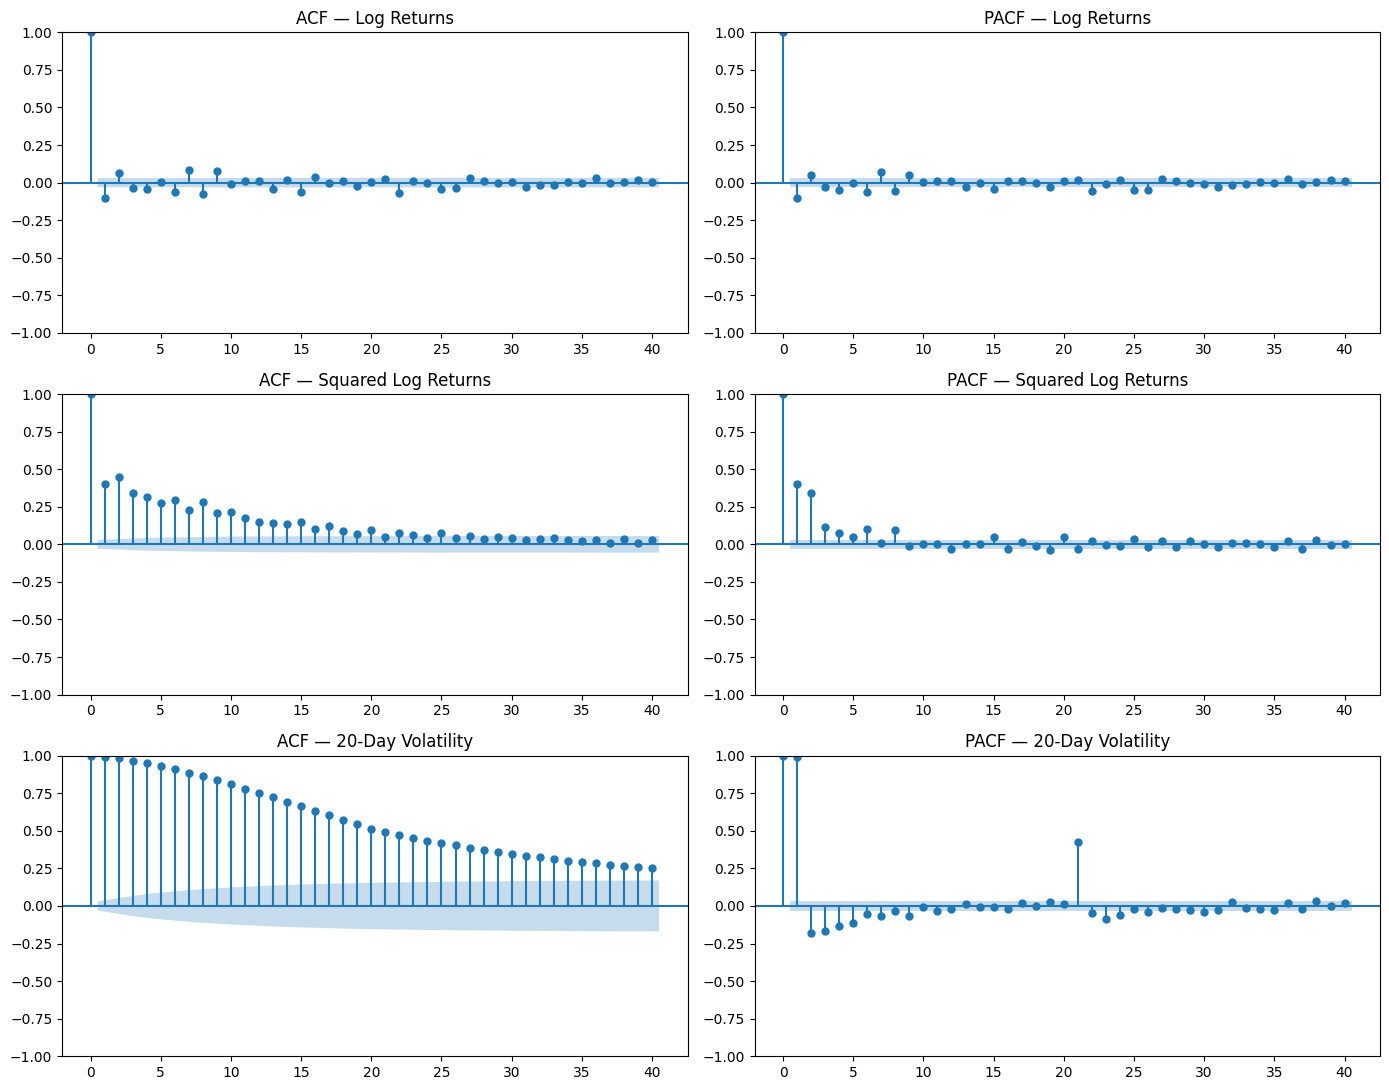

In [8]:
# Create three rows of ACF and PACF plots.
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

# Generate diagnostics for each series.
for i, (name, series) in enumerate(series_dict.items()):

    # Remove missing observations.
    values = series.dropna()

    # Plot the autocorrelation function.
    plot_acf(values, lags=40, ax=axes[i, 0])

    # Plot the partial autocorrelation function.
    plot_pacf(values, lags=40, method="ywm", ax=axes[i, 1])

    # Label both plots.
    axes[i, 0].set_title(f"ACF — {name}")
    axes[i, 1].set_title(f"PACF — {name}")

# Adjust spacing.
plt.tight_layout()

# Display the plots.
plt.show()


### 2.3.5 Observations and Conclusions

The ADF tests reject the unit-root null hypothesis for all three series: daily log returns, squared log returns, and 20-day historical volatility. This provides evidence against unit-root behavior but does not establish weak stationarity.

The ACF and PACF plots reveal substantial differences in their temporal dependence:

1. **Daily log returns:** Most autocorrelations are relatively small, suggesting limited linear predictability in returns.

2. **Squared log returns:** The ACF exhibits strong positive autocorrelation at short lags, followed by a gradual decay. This is consistent with volatility clustering: the magnitude of market fluctuations exhibits temporal dependence even when the returns themselves have weak linear autocorrelation.

3. **Historical volatility:** The 20-day volatility series exhibits very strong persistence. However, much of its short-lag autocorrelation is mechanically induced by the overlapping rolling windows. The prominent PACF spike near lag 20 may also be related to this construction.

These observations motivate modeling volatility-related quantities rather than relying exclusively on return forecasts.

In the next section, we will investigate classical autoregressive and moving-average models as interpretable baselines before introducing recurrent neural networks.


## 3. Classical Time-Series Models

In this section, we investigate classical statistical models for forecasting volatility-related quantities.

Our exploratory analysis revealed that daily log returns exhibit relatively weak linear autocorrelation, whereas squared returns exhibit substantial temporal dependence.

We therefore begin by modeling the squared daily log returns,

$$
X_t = r_t^2.
$$

We will introduce three closely related model families:

1. **Autoregressive (AR) models:** The current observation depends linearly on previous observations.
2. **Moving Average (MA) models:** The current observation depends linearly on present and previous random innovations.
3. **Autoregressive Moving Average (ARMA) models:** These combine autoregressive and moving-average components.

We will fit these models using the training data, select their hyperparameters using validation data, and evaluate their forecasts on the test period.

Our ultimate objective remains the Stage-0 binary classification task,

$$
y_t =
\mathbb{1}
\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{t,20}}
\right)>0.2
\right\}.
$$

Since ARMA models produce continuous forecasts, we must translate their squared-return forecasts into five-day realized-volatility forecasts before applying the classification threshold.

This conversion will be addressed explicitly after fitting the classical models.


### 3.1 Autoregressive Models

An **autoregressive model of order $p$**, denoted by AR($p$), is defined by

$$
X_t = c + \sum_{i=1}^{p}\phi_i X_{t-i}+\varepsilon_t,
$$

where:

- $X_t$ is the observation at time $t$.
- $p$ is the number of previous observations used.
- $\phi_1,\ldots,\phi_p$ are the autoregressive coefficients.
- $c$ is a constant.
- $\varepsilon_t$ is a random innovation.

For our introductory discussion, we assume that the innovations $\{\varepsilon_t\}$ are independent and identically distributed, with

$$
\mathbb{E}[\varepsilon_t]=0,
\qquad
\operatorname{Var}(\varepsilon_t)=\sigma_\varepsilon^2<\infty.
$$

We also assume that each innovation $\varepsilon_t$ is independent of the information available before time $t$.

The model describes a linear dependence of the current observation on its previous $p$ observations, together with a random innovation.

**Example: AR(1)**

Consider the autoregressive process

$$
X_t=0.5X_{t-1}+\varepsilon_t,
$$

where the innovations satisfy the assumptions above.

Suppose $X_{t-1}=2$. Then

$$
X_t=1+\varepsilon_t.
$$

Since $\varepsilon_t$ is independent of the past and has mean zero,

$$
\mathbb{E}[\varepsilon_t\mid X_{t-1}=2]=0.
$$

Therefore,

$$
\begin{aligned}
\mathbb{E}[X_t\mid X_{t-1}=2]
&=1+\mathbb{E}[\varepsilon_t\mid X_{t-1}=2]\\
&=1.
\end{aligned}
$$

Thus, the conditional expected value of the next observation is $1$, although the actual observation may differ because of the random innovation.

**Non-example**

Consider the nonlinear process

$$
X_t=X_{t-1}^2+\varepsilon_t.
$$

This is not an AR($p$) model in the classical linear sense because the dependence on the previous observation is nonlinear.

**Stationarity**

For an AR(1) process,

$$
X_t=c+\phi X_{t-1}+\varepsilon_t,
$$

the condition

$$
|\phi|<1
$$

ensures the existence of a causal weakly stationary solution under the innovation assumptions above.

For an AR($p$) process, the corresponding stationarity condition is that all roots of the characteristic polynomial

$$
1-\phi_1z-\phi_2z^2-\cdots-\phi_pz^p=0
$$

lie outside the unit circle.

In particular, AR models with arbitrary coefficients are not necessarily stationary.

### 3.2 Fitting Autoregressive Models

We begin by fitting autoregressive models to squared daily log returns,

$$
X_t=r_t^2.
$$

Our exploratory analysis showed that squared returns exhibit substantial temporal dependence, making them a natural starting point for volatility-related forecasting.

We will first examine AR(1) and AR(2), then investigate more general AR($p$) models.

To maintain consistency with Stage 0, we use the same chronological training, validation, and test periods:

- **Training:** Through December 31, 2020.
- **Validation:** January 2021 through December 2022.
- **Test:** January 2023 onward.

Model estimation and selection will use only the training and validation periods. The test period will remain untouched until final evaluation.

We will initially examine one-step-ahead forecasts and residual diagnostics. Subsequently, we will construct five-step-ahead forecasts for the original volatility classification task.


#### 3.2.1: Prepare the time series

In [9]:
# Compute squared daily log returns.
squared_returns = returns.pow(2)

# Select the training observations.
ar_train = squared_returns.loc[: "2020-12-31"]

# Select the validation observations.
ar_val = squared_returns.loc["2021-01-01":"2022-12-31"]

# Select the test observations.
ar_test = squared_returns.loc["2023-01-01":]

# Display the sizes of the three chronological splits.
print("Training observations:", len(ar_train))
print("Validation observations:", len(ar_val))
print("Test observations:", len(ar_test))

Training observations: 2768
Validation observations: 503
Test observations: 919


#### 3.2.2: Fit AR(1) and AR(2)

In [10]:
# Fit an AR(1) model to the training series.
ar1_model = ARIMA(ar_train, order=(1, 0, 0)).fit()

# Fit an AR(2) model to the same training series.
ar2_model = ARIMA(ar_train, order=(2, 0, 0)).fit()

# Display the estimated AR(1) model.
print(ar1_model.summary())

# Display the estimated AR(2) model.
print(ar2_model.summary())

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maxi

                               SARIMAX Results                                
Dep. Variable:             log_return   No. Observations:                 2768
Model:                 ARIMA(1, 0, 0)   Log Likelihood               17552.288
Date:                Mon, 16 Nov 2026   AIC                         -35098.577
Time:                        21:35:02   BIC                         -35080.799
Sample:                             0   HQIC                        -35092.156
                               - 2768                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0001   2.52e-05      4.728      0.000    6.98e-05       0.000
ar.L1          0.4555      0.003    174.829      0.000       0.450       0.461
sigma2      1.818e-07   7.24e-10    251.130      0.0

#### 3.2.3: Compare AR(1) and AR(2)

In [11]:
# Collect model information.
ar_comparison = pd.DataFrame({
    "Model": ["AR(1)", "AR(2)"],
    "AIC": [ar1_model.aic, ar2_model.aic],
    "BIC": [ar1_model.bic, ar2_model.bic],
})

# Display the comparison.
ar_comparison

,Model,AIC,BIC
0,AR(1),-35098.576758,-35080.799117
1,AR(2),-35703.606175,-35679.902654


#### Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC)

The **Akaike Information Criterion (AIC)** and **Bayesian Information Criterion (BIC)** are statistical criteria used for model selection. Both balance the goodness of fit of a model against its complexity.

### Akaike Information Criterion (AIC)

The AIC is defined as

$$
\boxed{\mathrm{AIC}=2k-2\log(\hat L)}
$$

where:

- $k$ is the number of estimated model parameters.
- $\hat L$ is the maximized likelihood of the observed data under the model.
- $\log(\hat L)$ is the maximized log-likelihood.

The AIC consists of two terms:

1. **Goodness of fit:** The term $-2\log(\hat L)$ decreases as the maximized likelihood increases.
2. **Complexity penalty:** The term $2k$ penalizes models with more estimated parameters.

A model with more parameters may fit the training data better, but the additional parameters must improve the likelihood sufficiently to compensate for the complexity penalty.

**Selection rule:** Among models fitted to the same observations using comparable likelihoods, the model with the **lowest AIC** is preferred.

**Example**

Suppose two models have the following properties:

| Model | Parameters ($k$) | Log-likelihood | AIC |
|---|---:|---:|---:|
| Model A | 2 | -100 | 204 |
| Model B | 5 | -97 | 204 |

Although Model B has a higher likelihood, it also has more parameters. Consequently, both models have the same AIC.

This illustrates how AIC balances goodness of fit against model complexity.

### Bayesian Information Criterion (BIC)

The BIC is defined as

$$
\boxed{\mathrm{BIC}=k\log(n)-2\log(\hat L)}
$$

where:

- $k$ is the number of estimated parameters.
- $n$ is the number of observations.
- $\hat L$ is the maximized likelihood.

Like AIC, BIC rewards goodness of fit while penalizing model complexity.

However, the complexity penalty is different:

$$
\underbrace{2k}_{\text{AIC penalty}}
\qquad\text{versus}\qquad
\underbrace{k\log(n)}_{\text{BIC penalty}}.
$$

For $n>e^2\approx7.39$, BIC imposes a larger penalty per additional parameter than AIC.

Therefore, for typical large datasets, BIC tends to favor simpler models than AIC.

**Selection rule:** Among comparable models, the model with the **lowest BIC** is preferred.

### Interpretation of Our Results

We fitted AR(1) and AR(2) models to squared SPY log returns using the same training dataset.

The results are:

| Model | AIC | BIC |
|---|---:|---:|
| AR(1) | -35098.58 | -35080.80 |
| AR(2) | -35703.61 | -35679.90 |

Both criteria favor AR(2):

$$
\mathrm{AIC}_{AR(2)} < \mathrm{AIC}_{AR(1)}
$$

and

$$
\mathrm{BIC}_{AR(2)} < \mathrm{BIC}_{AR(1)}.
$$

The differences are approximately

$$
\Delta\mathrm{AIC}=605.03,
$$

$$
\Delta\mathrm{BIC}=599.10.
$$

These differences strongly favor AR(2) according to both information criteria.

The result suggests that incorporating the second lag substantially improves the fitted model's likelihood, even after accounting for the additional parameter.

However, **a lower AIC or BIC does not guarantee better out-of-sample forecasting performance**.

In particular, our objective is to predict future volatility, so we must evaluate the models on the validation period before selecting the final autoregressive specification.


#### 3.2.4 Selecting the Autoregressive Order

We now investigate how the autoregressive order $p$ affects forecasting performance.

For an AR($p$) model,

$$
X_t=c+\sum_{i=1}^{p}\phi_iX_{t-i}+\varepsilon_t,
$$

the hyperparameter $p$ determines how many previous observations contribute to the prediction.

A larger value of $p$ allows the model to capture more temporal dependencies, but it also introduces additional parameters and may lead to overfitting.

We will compare candidate orders

$$
p\in\{1,2,3,5,10,20\}.
$$

Since squared daily returns are numerically small, we express them in squared percentage-return units:

$$
X_t=10^4r_t^2=(100r_t)^2.
$$

This rescaling improves numerical conditioning without changing the underlying temporal dependence.

We will use **validation mean squared error (MSE)** to select the autoregressive order:

$$
\mathrm{MSE}
=
\frac{1}{n}\sum_{t=1}^{n}(X_t-\hat X_t)^2.
$$

The selected order will be the one achieving the lowest validation MSE.

For this initial experiment, we evaluate one-step-ahead forecasts using the actual historical observations available before each prediction. The final five-day volatility classification task will require a separate multi-step forecasting evaluation.


Rescale the data:

In [12]:
# Express squared returns in squared percentage-return units.
scale_factor = 10_000

# Rescale the training observations.
ar_train_scaled = ar_train * scale_factor

# Rescale the validation observations.
ar_val_scaled = ar_val * scale_factor

Fit and evaluate AR(p) models:

In [13]:
# Autoregressive model estimation.
from statsmodels.tsa.ar_model import AutoReg

In [14]:
# Import regression evaluation metrics.
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Define candidate autoregressive orders.
ar_orders = [1, 2, 3, 5, 10, 20]

# Combine training and validation observations for lag construction.
ar_train_val_scaled = pd.concat([ar_train_scaled, ar_val_scaled])

# Store evaluation results.
ar_results = []

# Fit and evaluate each candidate order.
for p in ar_orders:

    # Fit the autoregressive model using training observations only.
    model = AutoReg(ar_train_scaled, lags=p, trend="c").fit()

    # Extract the intercept and autoregressive coefficients.
    coefficients = model.params.to_numpy()

    # Construct one-step predictions using observed historical values.
    predictions = []

    # Iterate through the validation observations.
    for date in ar_val_scaled.index:

        # Locate the current observation in the combined series.
        position = ar_train_val_scaled.index.get_loc(date)

        # Retrieve the preceding p observed squared returns.
        lagged_values = ar_train_val_scaled.iloc[position-p:position].to_numpy()

        # Compute the AR(p) prediction.
        prediction = coefficients[0] + np.dot(
            coefficients[1:], lagged_values[::-1]
        )

        # Store the prediction.
        predictions.append(prediction)

    # Compute validation errors.
    mse = mean_squared_error(ar_val_scaled, predictions)
    mae = mean_absolute_error(ar_val_scaled, predictions)

    # Record model complexity and forecasting performance.
    ar_results.append({
        "p": p,
        "AIC": model.aic,
        "BIC": model.bic,
        "Validation MSE": mse,
        "Validation MAE": mae,
    })

# Construct the results table.
ar_results_df = pd.DataFrame(ar_results)

# Display results ordered by validation MSE.
ar_results_df.sort_values("Validation MSE")

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so wil

,p,AIC,BIC,Validation MSE,Validation MAE
2,3,15270.049750,15299.673729,8.532762,1.625723
0,1,15884.841513,15902.618069,8.549128,1.660714
1,2,15275.048241,15298.748871,8.649958,1.634399
3,5,15233.633417,15275.101923,8.667025,1.637812
4,10,15118.654155,15189.721288,8.757414,1.651483
5,20,15037.045197,15167.255027,8.984812,1.687733


visualize validation performance:

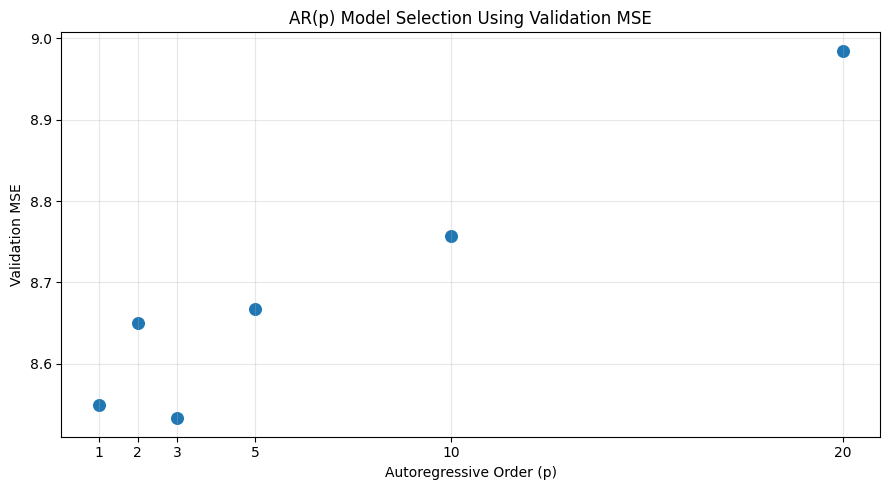

In [15]:
# Create the comparison plot.
plt.figure(figsize=(9, 5))

# Plot validation MSE for each candidate order.
plt.scatter(
    ar_results_df["p"],
    ar_results_df["Validation MSE"],
    s=70,
)

# Label the axes.
plt.xlabel("Autoregressive Order (p)")
plt.ylabel("Validation MSE")
plt.title("AR(p) Model Selection Using Validation MSE")

# Show the tested orders.
plt.xticks(ar_orders)

# Add a grid.
plt.grid(alpha=0.3)

# Display the plot.
plt.tight_layout()
plt.show()

Select the best order:

In [16]:
# Find the row with the lowest validation MSE.
best_ar_row = ar_results_df.loc[
    ar_results_df["Validation MSE"].idxmin()
]

# Extract the selected autoregressive order.
best_ar_order = int(best_ar_row["p"])

# Display the result.
print("Best AR order:", best_ar_order)
print("Validation MSE:", best_ar_row["Validation MSE"])
print("Validation MAE:", best_ar_row["Validation MAE"])

Best AR order: 3
Validation MSE: 8.532762289100225
Validation MAE: 1.6257229816915175


#### 3.2.5 Results and Interpretation

We evaluated autoregressive models with orders

$$
p\in\{1,2,3,5,10,20\}
$$

using one-step-ahead predictions on the validation period.

The results indicate that **AR(3) achieves the lowest validation MSE and MAE**, with

$$
\mathrm{MSE}=8.5328,
\qquad
\mathrm{MAE}=1.6257.
$$

The improvement in MSE over AR(1) is approximately $0.19\%$, indicating that the difference between these models is relatively small.

Increasing the autoregressive order beyond $p=3$ does not improve validation performance in this experiment. In particular, AR(10) and AR(20) exhibit larger forecasting errors.

Although AIC and BIC generally decrease with increasing model order, these criteria measure in-sample model fit with a complexity penalty, rather than validation forecasting performance. Furthermore, the default `AutoReg` fitting procedure uses different effective estimation samples for different orders, complicating direct comparisons of their information criteria.

We therefore select

$$
\boxed{p^*=3}
$$

as the best autoregressive order among the candidates tested, based on validation MSE.

This selection is provisional: the final prediction task involves five-day realized volatility rather than one-step-ahead squared returns. We will evaluate multi-step forecasts before determining the most suitable classical baseline.

#### 3.2.6 Comparing AR(3) with a Constant-Mean Baseline

Before proceeding to more complex time-series models, we investigate whether our selected AR(3) model outperforms a simple constant-mean predictor.

The **constant-mean baseline** predicts the same value for every future observation:

$$
\hat X_t=\bar X_{\mathrm{train}},
$$

where

$$
\bar X_{\mathrm{train}}
=
\frac{1}{N_{\mathrm{train}}}
\sum_{i\in\mathrm{train}}X_i.
$$

This baseline ignores temporal dependence entirely. Under squared-error loss, the sample mean minimizes the training error among constant predictions.

We compare the constant-mean baseline and AR(3) using one-step-ahead validation MSE and MAE.

To quantify the improvement, we also calculate the relative reduction in MSE:

$$
\mathrm{Improvement}(\%)
=
100\left(
1-\frac{\mathrm{MSE}_{AR(3)}}{\mathrm{MSE}_{\mathrm{mean}}}
\right).
$$

A positive value indicates that AR(3) outperforms the constant-mean baseline, while a negative value indicates that it performs worse.


Generate predictions:

In [17]:
# Fit the selected AR model using training observations only.
best_ar_model = AutoReg(
    ar_train_scaled,
    lags=best_ar_order,
    trend="c"
).fit()

# Extract the fitted coefficients.
best_ar_coefficients = best_ar_model.params.to_numpy()

# Store the AR predictions.
ar_predictions = []

# Generate one-step-ahead validation predictions.
for date in ar_val_scaled.index:

    # Locate the observation in the combined series.
    position = ar_train_val_scaled.index.get_loc(date)

    # Retrieve the preceding observed values.
    lagged_values = ar_train_val_scaled.iloc[
        position-best_ar_order:position
    ].to_numpy()

    # Compute the autoregressive prediction.
    prediction = (
        best_ar_coefficients[0]
        + np.dot(best_ar_coefficients[1:], lagged_values[::-1])
    )

    # Store the prediction.
    ar_predictions.append(prediction)

# Calculate the training mean.
training_mean = ar_train_scaled.mean()

# Predict the same training mean for every validation observation.
mean_predictions = np.full(len(ar_val_scaled), training_mean)

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


Compare the forecasting errors:

In [18]:
# Calculate validation errors for AR.
ar_mse = mean_squared_error(ar_val_scaled, ar_predictions)
ar_mae = mean_absolute_error(ar_val_scaled, ar_predictions)

# Calculate validation errors for the constant-mean baseline.
mean_mse = mean_squared_error(ar_val_scaled, mean_predictions)
mean_mae = mean_absolute_error(ar_val_scaled, mean_predictions)

# Construct the comparison table.
baseline_comparison = pd.DataFrame({
    "Model": ["Constant Mean", f"AR({best_ar_order})"],
    "Validation MSE": [mean_mse, ar_mse],
    "Validation MAE": [mean_mae, ar_mae],
})

# Display the results.
baseline_comparison

,Model,Validation MSE,Validation MAE
0,Constant Mean,7.631261,1.515050
1,AR(3),8.532762,1.625723


Calculate the relative improvement:

In [19]:
# Calculate the percentage reduction in MSE.
mse_improvement = 100 * (1 - ar_mse / mean_mse)

# Display the result.
print(f"AR({best_ar_order}) MSE improvement: {mse_improvement:.2f}%")

AR(3) MSE improvement: -11.81%


Visualize the forecasts:

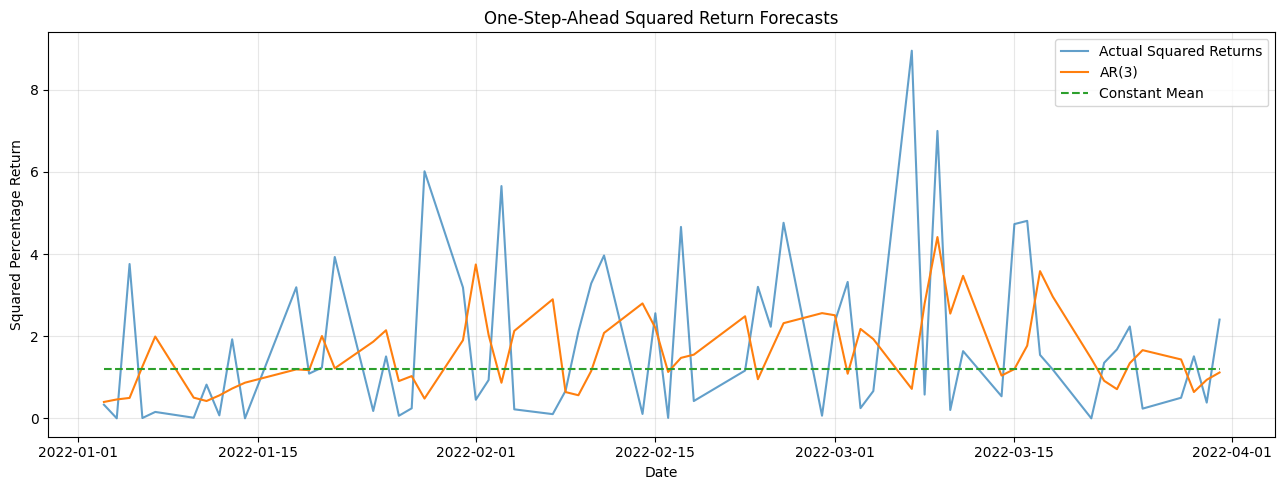

In [20]:
# Select a shorter validation interval for readability.
plot_dates = ar_val_scaled.loc["2022-01-01":"2022-03-31"].index

# Convert the AR predictions to a date-indexed series.
ar_pred_series = pd.Series(ar_predictions, index=ar_val_scaled.index)

# Convert the constant-mean predictions to a date-indexed series.
mean_pred_series = pd.Series(mean_predictions, index=ar_val_scaled.index)

# Create the plot.
plt.figure(figsize=(13, 5))

# Plot actual squared returns.
plt.plot(
    plot_dates,
    ar_val_scaled.loc[plot_dates],
    label="Actual Squared Returns",
    alpha=0.7,
)

# Plot AR predictions.
plt.plot(
    plot_dates,
    ar_pred_series.loc[plot_dates],
    label=f"AR({best_ar_order})",
)

# Plot constant-mean predictions.
plt.plot(
    plot_dates,
    mean_pred_series.loc[plot_dates],
    label="Constant Mean",
    linestyle="--",
)

# Add labels.
plt.title("One-Step-Ahead Squared Return Forecasts")
plt.xlabel("Date")
plt.ylabel("Squared Percentage Return")
plt.legend()
plt.grid(alpha=0.3)

# Display the plot.
plt.tight_layout()
plt.show()

#### Interpretation of the Forecasts

The constant-mean baseline produces a fixed prediction equal to the average squared return in the training period.

In contrast, the AR(3) model generates time-varying predictions based on the three preceding squared returns. Its forecasts respond to recent changes in return magnitude, suggesting that the model captures some linear temporal dependence.

However, the actual squared-return series contains sharp fluctuations that the AR(3) model does not consistently anticipate. In particular, several large volatility-related spikes are substantially underestimated.

The plot illustrates the difference between a constant predictor and a history-dependent predictor, but it does not establish which model has better overall forecasting performance.

We therefore use validation MSE and MAE to determine whether the autoregressive model improves upon the constant-mean baseline.


#### Comparison with the Constant-Mean Baseline

The validation results are:

| Model | Validation MSE | Validation MAE |
|---|---:|---:|
| Constant Mean | 7.6313 | 1.5151 |
| AR(3) | 8.5328 | 1.6257 |

The relative improvement in MSE is

$$
\begin{aligned}
\mathrm{Improvement}
&=100\left(1-\frac{8.5328}{7.6313}\right)\\
&\approx -11.81\%.
\end{aligned}
$$

Therefore, **AR(3) performs worse than the constant-mean baseline**, with approximately 11.81% higher validation MSE.

Although squared returns exhibit substantial autocorrelation, the selected autoregressive model does not translate this dependence into improved out-of-sample forecasting performance.

This may reflect distributional changes between training and validation, limitations of the linear autoregressive specification, or sensitivity to extreme squared returns.

The result illustrates an important distinction:

**Statistically detectable temporal dependence does not necessarily imply improved forecasting performance under a particular model.**

We retain the constant-mean predictor as a benchmark for subsequent classical time-series experiments.


### 3.3 Moving Average (MA) Models

#### 3.3.1: Mathematical Formulation
A **moving average model of order $q$**, denoted by MA($q$), is defined by

$$
X_t = \mu + \varepsilon_t + \sum_{j=1}^{q}\theta_j\varepsilon_{t-j},
$$

where:

- $X_t$ is the observation at time $t$.
- $\mu$ is the unconditional mean of the process.
- $q$ is the number of lagged innovations included.
- $\theta_1,\ldots,\theta_q$ are the moving-average coefficients.
- $\{\varepsilon_t\}$ is a sequence of independent, identically distributed innovations with mean zero and finite variance $\sigma_\varepsilon^2$.

The MA($q$) model describes the current observation as a linear combination of the present innovation and the previous $q$ innovations.

Unlike an autoregressive model, which depends explicitly on past observations, an MA model depends on past **innovations**.

#### Example: MA(1)

Consider

$$
X_t = 1 + \varepsilon_t + 0.5\varepsilon_{t-1},
$$

where $\{\varepsilon_t\}$ consists of independent, zero-mean innovations.

Suppose the previous innovation is known to be

$$
\varepsilon_{t-1}=2.
$$

Then

$$
X_t = 2+\varepsilon_t.
$$

Since $\varepsilon_t$ is independent of the past and has mean zero,

$$
\mathbb{E}[X_t\mid\varepsilon_{t-1}=2]=2.
$$

Thus, the expected observation depends on the previous innovation.

#### Non-example

Consider

$$
X_t = \varepsilon_t+\varepsilon_{t-1}^2.
$$

This is not a classical MA(1) model because the dependence on the previous innovation is nonlinear.

#### Stationarity

A finite-order MA($q$) process with independent, identically distributed innovations of finite variance is weakly stationary.

Its mean is

$$
\mathbb{E}[X_t]=\mu,
$$

and its variance is

$$
\operatorname{Var}(X_t)
=
\sigma_\varepsilon^2
\left(1+\sum_{j=1}^{q}\theta_j^2\right).
$$

Furthermore, its autocovariance satisfies

$$
\gamma(k)=0,\qquad |k|>q.
$$

Consequently, the ACF of an MA($q$) process cuts off after lag $q$.

This contrasts with a stationary AR process, whose ACF typically decays gradually.

#### Invertibility

An MA model is called **invertible** if its innovations can be recovered from the observed process through a convergent autoregressive representation.

For an MA(1) model,

$$
X_t=\mu+\varepsilon_t+\theta\varepsilon_{t-1},
$$

the invertibility condition is

$$
|\theta|<1.
$$

More generally, invertibility requires the roots of

$$
1+\theta_1z+\cdots+\theta_qz^q=0
$$

to lie outside the unit circle.

Invertibility is important for obtaining a well-defined, recoverable innovation representation from observed data.


#### 3.3.2: Fitting the model

In [21]:
# Define candidate moving-average orders.
ma_orders = [1, 2, 3, 5, 10, 20]

# Store fitted models and their information criteria.
ma_models = {}
ma_fit_results = []

# Fit each MA(q) model using the training data.
for q in ma_orders:

    # Estimate the moving-average model.
    model = ARIMA(
        ar_train_scaled,
        order=(0, 0, q),
        trend="c",
    ).fit()

    # Save the fitted model.
    ma_models[q] = model

    # Record its information criteria and convergence status.
    ma_fit_results.append({
        "q": q,
        "AIC": model.aic,
        "BIC": model.bic,
        "Converged": model.mle_retvals.get("converged", False),
    })

# Display the fitting results.
ma_fit_df = pd.DataFrame(ma_fit_results)

ma_fit_df

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so wil

,q,AIC,BIC,Converged
0,1,16206.251226,16224.028867,True
1,2,15530.199914,15553.903435,True
2,3,15432.687615,15462.317016,True
3,5,15374.000937,15415.482099,True
4,10,15206.127782,15277.238346,True
5,20,15114.893646,15245.263013,True


#### 3.3.3: Validation forecasts

In [22]:
# Store validation results.
ma_results = []

# Evaluate each successfully converged MA model.
for q, model in ma_models.items():

    # Skip models that did not converge.
    if not model.mle_retvals.get("converged", False):
        continue

    # Start with the model fitted on training data.
    current_model = model

    # Store one-step-ahead predictions.
    predictions = []

    # Process validation observations chronologically.
    for observation in ar_val_scaled:

        # Forecast the next squared return.
        forecast = current_model.forecast(steps=1)

        # Record the prediction.
        predictions.append(float(forecast.iloc[0]))

        # Update the state using the newly observed value.
        current_model = current_model.append(
            [observation],
            refit=False,
        )

    # Calculate validation errors.
    mse = mean_squared_error(ar_val_scaled, predictions)
    mae = mean_absolute_error(ar_val_scaled, predictions)

    # Store the results.
    ma_results.append({
        "q": q,
        "Validation MSE": mse,
        "Validation MAE": mae,
    })

# Create the comparison table.
ma_results_df = pd.DataFrame(ma_results)

# Display results ordered by validation MSE.
ma_results_df.sort_values("Validation MSE")

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `star

,q,Validation MSE,Validation MAE
0,1,7.840095,1.612592
4,10,8.906588,1.668859
5,20,9.060515,1.718788
3,5,9.221873,1.696431
2,3,9.302199,1.743003
1,2,9.488559,1.747856


#### 3.3.4: Compare with the constant-mean baseline

In [23]:
# Identify the best MA order using validation MSE.
best_ma_row = ma_results_df.loc[
    ma_results_df["Validation MSE"].idxmin()
]

# Extract the selected order.
best_ma_order = int(best_ma_row["q"])

# Compare the selected MA model with the existing baselines.
ma_baseline_comparison = pd.DataFrame({
    "Model": [
        "Constant Mean",
        f"AR({best_ar_order})",
        f"MA({best_ma_order})",
    ],
    "Validation MSE": [
        mean_mse,
        ar_mse,
        best_ma_row["Validation MSE"],
    ],
    "Validation MAE": [
        mean_mae,
        ar_mae,
        best_ma_row["Validation MAE"],
    ],
})

# Display the comparison.
ma_baseline_comparison

,Model,Validation MSE,Validation MAE
0,Constant Mean,7.631261,1.515050
1,AR(3),8.532762,1.625723
2,MA(1),7.840095,1.612592


#### 3.3.5 Results and Interpretation

We fitted MA($q$) models for

$$
q\in\{1,2,3,5,10,20\}
$$

and evaluated their one-step-ahead forecasts on the validation period.

All six models converged according to the optimizer's convergence indicator.

The lowest validation MSE was achieved by **MA(1)**:

$$
\mathrm{MSE}_{MA(1)}=7.8401,
$$

$$
\mathrm{MAE}_{MA(1)}=1.6126.
$$

However, the constant-mean baseline achieved a lower validation MSE of $7.6313$.

The relative MSE improvement of MA(1) over the constant-mean baseline is

$$
100\left(1-\frac{7.8401}{7.6313}\right)
\approx -2.74\%.
$$

Thus, MA(1) performs approximately $2.74\%$ worse than the constant-mean baseline in terms of validation MSE.

Although the AIC and BIC values decrease substantially as the MA order increases, the validation forecasting errors do not exhibit a corresponding improvement.

This demonstrates that model selection based on in-sample likelihood and model selection based on out-of-sample forecasting performance can produce different results.

**Conclusion:** MA(1) is the preferred MA model among the candidates tested, but it does not outperform the constant-mean benchmark.

We retain this result when investigating the combined ARMA model family.


### 3.4 Autoregressive Moving Average (ARMA) Models

#### 3.4.1 Mathematical formulation

An **autoregressive moving average model**, denoted by ARMA($p,q$), combines autoregressive and moving-average components.

It is defined by

$$
X_t
=
c
+
\sum_{i=1}^{p}\phi_i X_{t-i}
+
\varepsilon_t
+
\sum_{j=1}^{q}\theta_j\varepsilon_{t-j},
$$

where:

- $p$ is the autoregressive order.
- $q$ is the moving-average order.
- $\phi_1,\ldots,\phi_p$ are the autoregressive coefficients.
- $\theta_1,\ldots,\theta_q$ are the moving-average coefficients.
- $c$ is a constant.
- $\{\varepsilon_t\}$ is a sequence of independent, zero-mean innovations with finite variance.

The model combines two sources of temporal dependence:

1. **Autoregressive dependence:** The current observation depends linearly on previous observations.
2. **Moving-average dependence:** The current observation depends linearly on previous innovations.

The AR and MA models are special cases:

$$
\operatorname{AR}(p)=\operatorname{ARMA}(p,0),
$$

$$
\operatorname{MA}(q)=\operatorname{ARMA}(0,q).
$$

#### Example: ARMA(1,1)

Consider

$$
X_t=0.5X_{t-1}+\varepsilon_t+0.3\varepsilon_{t-1},
$$

where the innovations are independent, have mean zero, and have finite variance.

Suppose

$$
X_{t-1}=2,
\qquad
\varepsilon_{t-1}=1.
$$

Then

$$
X_t=0.5(2)+0.3(1)+\varepsilon_t
=1.3+\varepsilon_t.
$$

Since the current innovation is independent of the past and has mean zero,

$$
\mathbb{E}[X_t\mid X_{t-1}=2,\varepsilon_{t-1}=1]
=1.3.
$$

Thus, the conditional expected value depends on both the previous observation and the previous innovation.

#### Non-example

Consider

$$
X_t=X_{t-1}^2+\varepsilon_t+0.3\varepsilon_{t-1}.
$$

This is not a classical ARMA model because its dependence on the previous observation is nonlinear.

#### Stationarity and Invertibility

For a causal stationary ARMA($p,q$) model, the roots of the autoregressive polynomial

$$
\Phi(z)=1-\phi_1z-\cdots-\phi_pz^p
$$

must lie outside the unit circle.

For invertibility, the roots of the moving-average polynomial

$$
\Theta(z)=1+\theta_1z+\cdots+\theta_qz^q
$$

must also lie outside the unit circle.

These conditions ensure that the model admits a stable causal representation and that its innovations can be recovered from the observed process.

#### Application to Volatility Prediction

As in the preceding experiments, we model squared daily log returns:

$$
X_t=10^4r_t^2.
$$

We investigate whether combining autoregressive and moving-average terms improves one-step-ahead forecasting performance.

Our candidate orders are

$$
p,q\in\{1,2,3\}.
$$

The final model will be selected using validation MSE rather than training likelihood alone.


#### 3.4.2: Fitting ARMA models
To avoid the repeated date-frequency warnings from the MA experiments, we'll pass the training series as a NumPy array. The observation order remains unchanged.

In [24]:
# Define candidate autoregressive orders.
arma_p_orders = [1, 2, 3]

# Define candidate moving-average orders.
arma_q_orders = [1, 2, 3]

# Convert the training data to a NumPy array.
arma_train = ar_train_scaled.to_numpy()

# Store the fitted models.
arma_models = {}

# Store fitting diagnostics.
arma_fit_results = []

# Iterate over candidate autoregressive orders.
for p in arma_p_orders:

    # Iterate over candidate moving-average orders.
    for q in arma_q_orders:

        # Fit the ARMA(p, q) model.
        model = ARIMA(
            arma_train,
            order=(p, 0, q),
            trend="c",
        ).fit()

        # Check whether optimization converged.
        converged = model.mle_retvals.get("converged", False)

        # Store the fitted model.
        arma_models[(p, q)] = model

        # Record fitting diagnostics.
        arma_fit_results.append({
            "p": p,
            "q": q,
            "AIC": model.aic,
            "BIC": model.bic,
            "Converged": converged,
        })

# Construct the fitting-results table.
arma_fit_df = pd.DataFrame(arma_fit_results)

# Display the results.
arma_fit_df

/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/opt/anaconda3/envs/finance/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,p,q,AIC,BIC,Converged
0,1,1,15411.839401,15435.542923,True
1,1,2,15353.224260,15382.853661,True
2,1,3,15200.150583,15235.705864,True
3,2,1,15284.331525,15313.960927,True
4,2,2,15285.674859,15321.230141,True
5,2,3,15202.143962,15243.625125,True
6,3,1,15285.645456,15321.200738,True
7,3,2,15285.190453,15326.671615,True
8,3,3,15195.130370,15242.537413,True


#### 3.4.3 One-step=ahead validation forecasts
We use the same evaluation procedure as in the MA experiment:
- Estimate model parameters using training data only.
- Forecast the next observation.
- Observe the actual value.
- Update the model's state without re-estimating parameters.
- Repeat throughout the validation period.

In [25]:
# Convert validation observations to a NumPy array.
arma_val = ar_val_scaled.to_numpy()

# Store validation results.
arma_results = []

# Evaluate each fitted ARMA model.
for (p, q), model in arma_models.items():

    # Skip models that did not converge.
    if not model.mle_retvals.get("converged", False):
        continue

    # Initialize the forecasting model.
    current_model = model

    # Store one-step-ahead predictions.
    predictions = []

    # Process validation observations chronologically.
    for observation in arma_val:

        # Forecast the next squared return.
        forecast = current_model.forecast(steps=1)

        # Store the forecast.
        predictions.append(float(forecast[0]))

        # Update the model state with the observed value.
        current_model = current_model.append(
            [observation],
            refit=False,
        )

    # Calculate validation MSE.
    mse = mean_squared_error(arma_val, predictions)

    # Calculate validation MAE.
    mae = mean_absolute_error(arma_val, predictions)

    # Record forecasting performance.
    arma_results.append({
        "p": p,
        "q": q,
        "Validation MSE": mse,
        "Validation MAE": mae,
    })

# Construct the validation-results table.
arma_results_df = pd.DataFrame(arma_results)

# Display models ordered by validation MSE.
arma_results_df.sort_values("Validation MSE")

,p,q,Validation MSE,Validation MAE
0,1,1,7.635692,1.582931
4,2,2,8.415233,1.619680
3,2,1,8.521669,1.624878
6,3,1,8.553474,1.625507
1,1,2,8.652074,1.659126
8,3,3,8.656606,1.650145
5,2,3,8.714826,1.647802
2,1,3,8.714967,1.647983
7,3,2,8.847921,1.650712


#### 3.4.4 Visualizing validation performance
Since we are comparing two discrete hyperparameters, a heatmap may be useful.

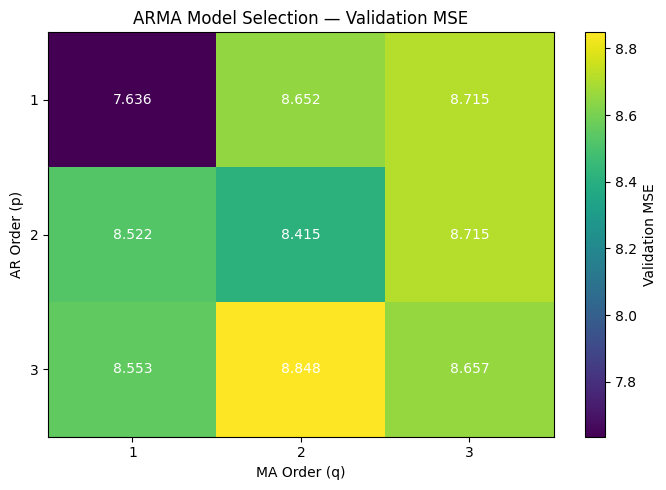

In [26]:
# Arrange validation MSE values by AR and MA orders.
arma_mse_grid = arma_results_df.pivot(
    index="p",
    columns="q",
    values="Validation MSE",
)

# Create the heatmap.
fig, ax = plt.subplots(figsize=(7, 5))

# Display the MSE matrix.
image = ax.imshow(arma_mse_grid, aspect="auto", cmap="viridis")

# Label the axes.
ax.set_xlabel("MA Order (q)")
ax.set_ylabel("AR Order (p)")
ax.set_title("ARMA Model Selection — Validation MSE")

# Display the tested orders.
ax.set_xticks(range(len(arma_mse_grid.columns)))
ax.set_xticklabels(arma_mse_grid.columns)

ax.set_yticks(range(len(arma_mse_grid.index)))
ax.set_yticklabels(arma_mse_grid.index)

# Display the MSE inside each cell.
for i in range(len(arma_mse_grid.index)):
    for j in range(len(arma_mse_grid.columns)):

        # Extract the validation MSE.
        value = arma_mse_grid.iloc[i, j]

        # Annotate available values.
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.3f}",
                ha="center",
                va="center",
                color="white",
            )

# Add the color scale.
fig.colorbar(image, ax=ax, label="Validation MSE")

# Display the figure.
plt.tight_layout()
plt.show()

#### 3.4.5 Select the best ARMA model
We will select the best model programmatically, using the same criterion as before.

In [27]:
# Identify the model with the lowest validation MSE.
best_arma_row = arma_results_df.loc[
    arma_results_df["Validation MSE"].idxmin()
]

# Extract the selected autoregressive order.
best_arma_p = int(best_arma_row["p"])

# Extract the selected moving-average order.
best_arma_q = int(best_arma_row["q"])

# Display the selected model.
print(f"Best ARMA model: ARMA({best_arma_p}, {best_arma_q})")
print(f"Validation MSE: {best_arma_row['Validation MSE']:.6f}")
print(f"Validation MAE: {best_arma_row['Validation MAE']:.6f}")

Best ARMA model: ARMA(1, 1)
Validation MSE: 7.635692
Validation MAE: 1.582931


#### 3.4.6 Compare all classical baselines
Finally, we'll compare the best ARMA model against the constant mean, AR(3), and MA(1).

In [28]:
# Construct the classical-model comparison table.
classical_comparison = pd.DataFrame({
    "Model": [
        "Constant Mean",
        f"AR({best_ar_order})",
        f"MA({best_ma_order})",
        f"ARMA({best_arma_p}, {best_arma_q})",
    ],
    "Validation MSE": [
        mean_mse,
        ar_mse,
        best_ma_row["Validation MSE"],
        best_arma_row["Validation MSE"],
    ],
    "Validation MAE": [
        mean_mae,
        ar_mae,
        best_ma_row["Validation MAE"],
        best_arma_row["Validation MAE"],
    ],
})

# Display models in order of validation MSE.
classical_comparison.sort_values("Validation MSE")

,Model,Validation MSE,Validation MAE
0,Constant Mean,7.631261,1.515050
3,"ARMA(1, 1)",7.635692,1.582931
2,MA(1),7.840095,1.612592
1,AR(3),8.532762,1.625723


#### 3.4.7 Results and Interpretation

We evaluated nine ARMA($p,q$) models with

$$
p,q\in\{1,2,3\}
$$

using rolling one-step-ahead forecasts on the validation period.

The best-performing specification was

$$
\boxed{\operatorname{ARMA}(1,1)}
$$

with

$$
\mathrm{MSE}=7.635692,
\qquad
\mathrm{MAE}=1.582931.
$$

The selected ARMA model outperformed the previously selected AR(3) and MA(1) models in terms of validation MSE.

However, the constant-mean baseline remained the best-performing model:

| Model | Validation MSE | Validation MAE |
|---|---:|---:|
| Constant Mean | 7.631261 | 1.515050 |
| ARMA(1,1) | 7.635692 | 1.582931 |
| MA(1) | 7.840095 | 1.612592 |
| AR(3) | 8.532762 | 1.625723 |

The relative improvement of ARMA(1,1) over the constant-mean baseline is

$$
100\left(1-\frac{7.635692}{7.631261}\right)
\approx -0.058\%.
$$

Thus, ARMA(1,1) achieves nearly the same validation MSE as the constant-mean predictor, but does not improve upon it.

Increasing the AR and MA orders generally did not produce better validation performance among the candidates tested.

**Conclusion:** Although squared returns exhibit substantial temporal autocorrelation, the classical AR, MA, and ARMA models considered here do not outperform the constant-mean benchmark in one-step-ahead squared-return forecasting.

This does not establish that squared returns are unpredictable or that more sophisticated volatility models cannot improve forecasting performance. It indicates only that the particular linear models and estimation procedures tested here did not provide an improvement under our chosen validation metric.

The next step is to investigate whether these models provide useful forecasts for the original five-day volatility prediction task.

### 3.5 Five-Day Realized Volatility Forecasting Using ARMA

#### 3.5.1: Mathematical formulation

Our preceding experiments investigated one-step-ahead forecasts of squared daily log returns. We now return to the original forecasting objective: predicting realized volatility over the next five trading days.

The five-day realized volatility is defined by

$$
RV_{t,t+5}
=
\sqrt{\frac{1}{5}\sum_{k=1}^{5}r_{t+k}^2},
$$

where $r_t$ denotes the daily log return.

We fitted the ARMA models to the rescaled squared returns,

$$
X_t=10^4r_t^2.
$$

At time $t$, the ARMA model produces forecasts

$$
\hat X_{t+1|t},\ldots,\hat X_{t+5|t}.
$$

These are forecasts made using only observations available through time $t$.

Since squared returns are nonnegative but ARMA forecasts are not necessarily nonnegative, we use the following transformation:

$$
\hat X_{t+k|t}^{+}
=
\max\left(0,\hat X_{t+k|t}\right).
$$

We then construct the five-day volatility forecast:

$$
\boxed{
\widehat{RV}_{t,t+5}
=
\sqrt{
\frac{1}{5\times10^4}
\sum_{k=1}^{5}
\hat X_{t+k|t}^{+}
}.
}
$$

The factor $10^4$ reverses the scaling applied during model estimation.

**Important:** Clipping negative forecasts is a practical approximation, not a property of the ARMA model itself. Furthermore, the square root of the forecasted average squared return is not generally equal to the conditional expectation of realized volatility.

#### Evaluation

We will evaluate the five-day volatility forecasts using mean squared error and mean absolute error:

$$
\mathrm{MSE}
=
\frac{1}{N}\sum_{t=1}^{N}
\left(RV_{t,t+5}-\widehat{RV}_{t,t+5}\right)^2,
$$

$$
\mathrm{MAE}
=
\frac{1}{N}\sum_{t=1}^{N}
\left|RV_{t,t+5}-\widehat{RV}_{t,t+5}\right|.
$$

We will also convert the forecasts into binary predictions using the original Stage-0 target:

$$
y_t=
\mathbb{1}
\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{t,20}}
\right)>0.2
\right\}.
$$

The predicted label is

$$
\hat y_t=
\mathbb{1}
\left\{
\widehat{RV}_{t,t+5}
>
e^{0.2}Vol_{t,20}
\right\}.
$$

This allows us to compare the classical time-series baseline with the classification models developed in Stage 0.


#### 3.5.2 Generate five-day ARMA forecasts
We'll reuse arma_models, best_arma_p, best_arma_q, and ar_val_scaled from the preceding experiments.

One important detail: the last four validation dates do not have complete five-day outcomes within the validation period. We will therefore evaluate only dates for which all five future returns belong to the validation period.

This keeps our initial validation experiment independent of the test period.

In [29]:
# Retrieve the selected ARMA model fitted on training data.
arma_five_day_model = arma_models[(best_arma_p, best_arma_q)]

# Store the five-day volatility forecasts.
arma_rv_predictions = []

# Store the corresponding forecast dates.
arma_rv_dates = []

# Start with the fitted training model.
current_model = arma_five_day_model

# Iterate over validation observations.
for i, observation in enumerate(ar_val_scaled):

    # Incorporate the current day's observed squared return.
    current_model = current_model.append(
        [observation],
        refit=False,
    )

    # Exclude dates without five complete future validation observations.
    if i + 5 >= len(ar_val_scaled):
        continue

    # Forecast the next five squared returns.
    forecast = np.asarray(current_model.forecast(steps=5))

    # Replace negative squared-return forecasts with zero.
    forecast = np.maximum(forecast, 0.0)

    # Convert the five squared-return forecasts to realized volatility.
    predicted_rv = np.sqrt(forecast.mean() / scale_factor)

    # Store the forecast.
    arma_rv_predictions.append(predicted_rv)

    # Store the corresponding date.
    arma_rv_dates.append(ar_val_scaled.index[i])

# Construct the date-indexed forecast series.
arma_rv_pred = pd.Series(
    arma_rv_predictions,
    index=arma_rv_dates,
    name="Predicted RV",
)

# Display the first few forecasts.
arma_rv_pred.head()

2021-01-04    0.009621
2021-01-05    0.009218
2021-01-06    0.008796
2021-01-07    0.010739
2021-01-08    0.009806
Name: Predicted RV, dtype: float64

#### 3.5.3 Construct the actual five-day realized volatility
We can compute the realized volatility directly from the original log-return series.

In [30]:
# Calculate the squared daily log returns.
squared_returns_original = returns.pow(2)

# Calculate the average of the next five squared returns.
future_mean_squared_returns = sum(
    squared_returns_original.shift(-k)
    for k in range(1, 6)
) / 5

# Calculate actual five-day realized volatility.
realized_volatility_5d = np.sqrt(future_mean_squared_returns)

# Align actual volatility with the forecast dates.
arma_rv_actual = realized_volatility_5d.loc[arma_rv_pred.index]

# Construct the comparison table.
arma_rv_comparison = pd.DataFrame({
    "Actual RV": arma_rv_actual,
    "Predicted RV": arma_rv_pred,
})

# Display the first few observations.
arma_rv_comparison.head()

,Actual RV,Predicted RV
2021-01-04,0.008697,0.009621
2021-01-05,0.008138,0.009218
2021-01-06,0.007782,0.008796
2021-01-07,0.004418,0.010739
2021-01-08,0.004877,0.009806


#### 3.5.4 Evaluate volatility forecasting performance

In [31]:
# Calculate five-day realized-volatility MSE.
arma_rv_mse = mean_squared_error(
    arma_rv_comparison["Actual RV"],
    arma_rv_comparison["Predicted RV"],
)

# Calculate five-day realized-volatility MAE.
arma_rv_mae = mean_absolute_error(
    arma_rv_comparison["Actual RV"],
    arma_rv_comparison["Predicted RV"],
)

# Display the results.
print(f"Five-day RV MSE: {arma_rv_mse:.8f}")
print(f"Five-day RV MAE: {arma_rv_mae:.6f}")

Five-day RV MSE: 0.00002365
Five-day RV MAE: 0.003731


#### 3.5.5 Visualize actual and predicted volatility
We'll plot a portion of the validation period so that we can inspect whether the ARMA forecasts respond to changing volatility.

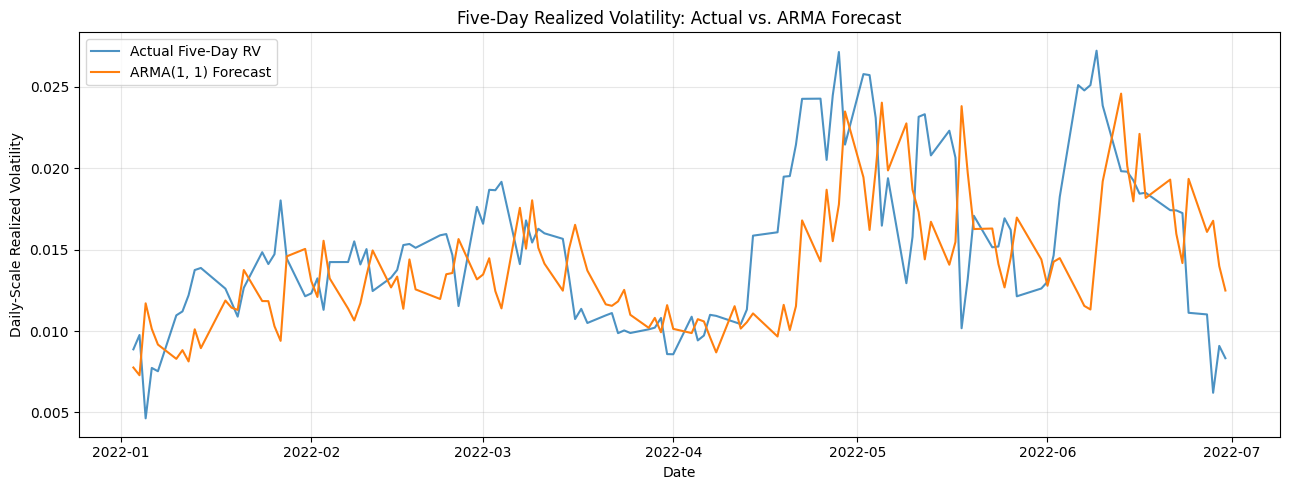

In [32]:
# Select the plotting period.
rv_plot = arma_rv_comparison.loc["2022-01-01":"2022-06-30"]

# Create the figure.
plt.figure(figsize=(13, 5))

# Plot actual five-day realized volatility.
plt.plot(
    rv_plot.index,
    rv_plot["Actual RV"],
    label="Actual Five-Day RV",
    alpha=0.8,
)

# Plot predicted five-day realized volatility.
plt.plot(
    rv_plot.index,
    rv_plot["Predicted RV"],
    label=f"ARMA({best_arma_p}, {best_arma_q}) Forecast",
)

# Add labels and formatting.
plt.title("Five-Day Realized Volatility: Actual vs. ARMA Forecast")
plt.xlabel("Date")
plt.ylabel("Daily-Scale Realized Volatility")
plt.legend()
plt.grid(alpha=0.3)

# Display the plot.
plt.tight_layout()
plt.show()

**Observation:** The forecast curve appears to be shifted version of the actual five-day RV curve.

Let's test whether there is a systematic lag
We can calculate correlations between the actual volatility series and the predicted series at different shifts.

Importantly, this is a diagnostic, not a way to improve the model by using future information.

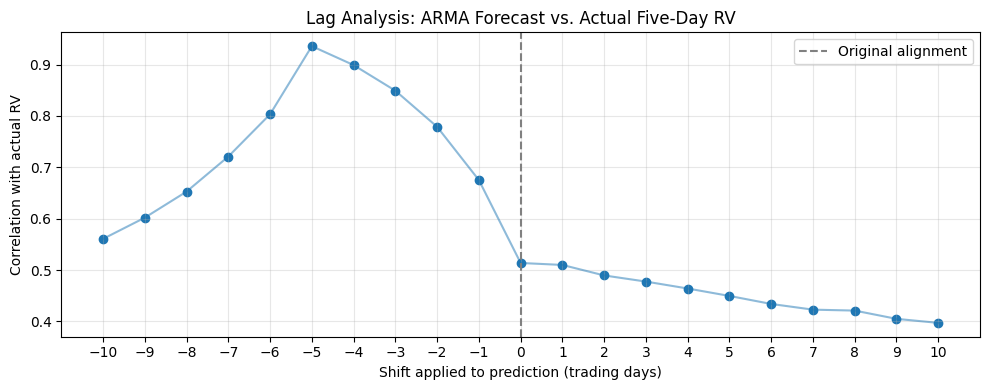

In [33]:
# Define the range of shifts to investigate.
lags = range(-10, 11)

# Store the correlations for each shift.
lag_correlations = []

# Calculate correlations between actual and shifted predictions.
for lag in lags:

    # Shift the predicted volatility series.
    shifted_prediction = arma_rv_comparison["Predicted RV"].shift(lag)

    # Calculate its correlation with actual volatility.
    correlation = arma_rv_comparison["Actual RV"].corr(
        shifted_prediction
    )

    # Store the correlation.
    lag_correlations.append(correlation)

# Plot correlation against the shift.
plt.figure(figsize=(10, 4))

# Display the lag correlations.
plt.scatter(lags, lag_correlations)

# Connect the points to show the pattern.
plt.plot(lags, lag_correlations, alpha=0.5)

# Mark the original alignment.
plt.axvline(0, linestyle="--", color="gray", label="Original alignment")

# Add labels.
plt.xlabel("Shift applied to prediction (trading days)")
plt.ylabel("Correlation with actual RV")
plt.title("Lag Analysis: ARMA Forecast vs. Actual Five-Day RV")
plt.xticks(list(lags))
plt.legend()
plt.grid(alpha=0.3)

# Display the plot.
plt.tight_layout()
plt.show()

#### Lag analysis: Forecast timing and volatility persistence

The lag-correlation analysis reveals that the correlation between actual and predicted five-day realized volatility is approximately $0.51$ at the original alignment, but increases to approximately $0.94$ when the predicted series is shifted backward by five trading days.

This suggests that the ARMA(1,1) forecasts respond to volatility changes with a delay.

The result is partly explained by the forward-looking construction of realized volatility:

$$
RV_{t,t+5}
=
\sqrt{\frac15\sum_{k=1}^{5}r_{t+k}^2}.
$$

A large return occurring on day $s$ affects realized-volatility targets associated with the preceding five forecast origins, whereas the ARMA model cannot incorporate that return until day $s$.

The high correlation at lag $-5$ must not be interpreted as forecasting accuracy: the shifted predictions use observations unavailable at the original forecast origin.

Therefore, all predictive evaluations retain the original time alignment.



### 3.5.6 Binary Classification Using ARMA

Our original objective is to predict whether future five-day realized volatility will exceed the current 20-day historical volatility by a specified factor.

Recall that the classification target is

$$
y_t
=
\mathbb{1}
\left\{
\log\left(
\frac{RV_{t,t+5}}{Vol_{t,20}}
\right)>0.2
\right\}.
$$

Equivalently,

$$
y_t
=
\mathbb{1}
\left\{
RV_{t,t+5}>e^{0.2}Vol_{t,20}
\right\}.
$$

Using our ARMA forecast, we construct the predicted label

$$
\hat y_t
=
\mathbb{1}
\left\{
\widehat{RV}_{t,t+5}>e^{0.2}Vol_{t,20}
\right\}.
$$

Here, $Vol_{t,20}$ is computed using only returns observed through day $t$.

We will evaluate the resulting predictions using accuracy, balanced accuracy, precision, recall, F1-score, and a confusion matrix.

Since the ARMA model produces volatility point forecasts rather than calibrated probabilities of the positive class, we will not calculate ROC-AUC, PR-AUC, or probabilistic log loss at this stage.


Step 1: Calculate historical 20-day volatility:

In [34]:
# Calculate the historical 20-day realized volatility.
historical_volatility_20d = np.sqrt(
    returns.pow(2).rolling(window=20).mean()
)

# Align historical volatility with our ARMA forecast dates.
arma_rv_comparison["Historical Vol 20D"] = (
    historical_volatility_20d.reindex(arma_rv_comparison.index)
)

# Verify that the required values are available.
print(arma_rv_comparison.isna().sum())

# Display the first few observations.
arma_rv_comparison.head()

Actual RV             0
Predicted RV          0
Historical Vol 20D    0
dtype: int64


,Actual RV,Predicted RV,Historical Vol 20D
2021-01-04,0.008697,0.009621,0.006095
2021-01-05,0.008138,0.009218,0.005986
2021-01-06,0.007782,0.008796,0.006115
2021-01-07,0.004418,0.010739,0.006917
2021-01-08,0.004877,0.009806,0.006738


Step 2: Construct actual and predicted labels

In [35]:
# Define the original Stage-0 log-volatility threshold.
volatility_threshold = 0.2

# Convert the log threshold to a multiplicative factor.
volatility_factor = np.exp(volatility_threshold)

# Calculate the volatility level required for a positive classification.
arma_rv_comparison["Classification Threshold"] = (
    volatility_factor * arma_rv_comparison["Historical Vol 20D"]
)

# Construct the actual binary labels.
arma_rv_comparison["Actual Label"] = (
    arma_rv_comparison["Actual RV"]
    > arma_rv_comparison["Classification Threshold"]
).astype(int)

# Construct the predicted binary labels.
arma_rv_comparison["Predicted Label"] = (
    arma_rv_comparison["Predicted RV"]
    > arma_rv_comparison["Classification Threshold"]
).astype(int)

# Inspect the resulting classification data.
arma_rv_comparison.head(10)

,Actual RV,Predicted RV,Historical Vol 20D,Classification Threshold,Actual Label,Predicted Label
2021-01-04,0.008697,0.009621,0.006095,0.007445,1,1
2021-01-05,0.008138,0.009218,0.005986,0.007311,1,1
2021-01-06,0.007782,0.008796,0.006115,0.007469,1,1
2021-01-07,0.004418,0.010739,0.006917,0.008448,0,1
2021-01-08,0.004877,0.009806,0.006738,0.008230,0,1
2021-01-11,0.005183,0.009326,0.006905,0.008434,0,1
2021-01-12,0.008040,0.008384,0.006900,0.008428,0,0
2021-01-13,0.007960,0.007825,0.006853,0.008371,0,0
2021-01-14,0.007963,0.007523,0.006210,0.007585,1,0
2021-01-15,0.007469,0.007958,0.006413,0.007832,0,1


Step 3: Evaluate classification performance

In [36]:
# Import the classification evaluation metrics.
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Extract the actual labels.
y_true = arma_rv_comparison["Actual Label"]

# Extract the predicted labels.
y_pred = arma_rv_comparison["Predicted Label"]

# Calculate the classification metrics.
arma_classification_results = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1": f1_score(y_true, y_pred, zero_division=0),
}

# Display the metrics as a table.
pd.DataFrame(
    arma_classification_results.items(),
    columns=["Metric", "ARMA(1,1)"],
)

,Metric,"ARMA(1,1)"
0,Accuracy,0.710843
1,Balanced Accuracy,0.630632
2,Precision,0.433824
3,Recall,0.468254
4,F1,0.450382


Step 4: Examine the confusion matrix

In [37]:
# Calculate the confusion matrix.
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Display the confusion matrix.
print("Confusion Matrix:")
print(cm)

# Display the detailed classification report.
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Confusion Matrix:
[[295  77]
 [ 67  59]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80       372
           1       0.43      0.47      0.45       126

    accuracy                           0.71       498
   macro avg       0.62      0.63      0.63       498
weighted avg       0.72      0.71      0.71       498



Step 5: Compare against a simple baseline

In [38]:
# Determine the majority class in the validation labels.
majority_class = y_true.mode().iloc[0]

# Construct constant majority-class predictions.
majority_predictions = np.full(len(y_true), majority_class)

# Evaluate the majority-class baseline.
majority_results = {
    "Accuracy": accuracy_score(y_true, majority_predictions),
    "Balanced Accuracy": balanced_accuracy_score(y_true, majority_predictions),
    "Precision": precision_score(y_true, majority_predictions, zero_division=0),
    "Recall": recall_score(y_true, majority_predictions, zero_division=0),
    "F1": f1_score(y_true, majority_predictions, zero_division=0),
}

# Compare ARMA with the majority-class baseline.
classification_comparison = pd.DataFrame({
    "ARMA(1,1)": arma_classification_results,
    "Majority Class": majority_results,
})

# Display the comparison.
classification_comparison

,"ARMA(1,1)",Majority Class
Accuracy,0.710843,0.746988
Balanced Accuracy,0.630632,0.500000
Precision,0.433824,0.000000
Recall,0.468254,0.000000
F1,0.450382,0.000000


We should also inspect the fraction of actual positive events and the fraction predicted positive:

In [39]:
# Calculate the observed positive-class proportion.
actual_positive_rate = y_true.mean()

# Calculate the predicted positive-class proportion.
predicted_positive_rate = y_pred.mean()

# Display both proportions.
print(f"Actual positive rate: {actual_positive_rate:.2%}")
print(f"Predicted positive rate: {predicted_positive_rate:.2%}")

Actual positive rate: 25.30%
Predicted positive rate: 27.31%


#### Interpretation of ARMA(1,1) Classification Results

The ARMA(1,1) model achieves a validation accuracy of approximately 71.08%, balanced accuracy of 63.06%, and F1-score of 45.04%.

Although its overall accuracy is lower than that of the majority-class baseline (74.70%), ARMA performs substantially better at identifying volatility-increase events.

The model correctly identifies 59 of the 126 positive events, corresponding to a recall of 46.83%. Its precision is 43.38%, indicating that fewer than half of its positive predictions correspond to actual volatility increases.

The predicted positive-class proportion (27.31%) is close to the observed proportion (25.30%), although this does not guarantee accurate event identification.

These results suggest that the ARMA model captures some predictive information from historical squared returns, but its ability to anticipate future volatility increases remains limited.

The model will serve as an exploratory classical time-series baseline for subsequent neural sequence models.

### 3.6 Saving the Classical Time-Series Baseline

We have completed our initial experiments with autoregressive (AR), moving-average (MA), and autoregressive moving-average (ARMA) models.

Among the candidate ARMA models, ARMA(1,1) achieved the lowest one-step-ahead validation MSE. We subsequently used this model to forecast five-day realized volatility and predict volatility-increase events.

We now save the fitted model, its forecasts, classification labels, and evaluation metrics for comparison with neural sequence models.

The saved ARMA model was fitted using training observations only. Its validation forecasts were generated sequentially using observed returns available at each forecast origin, without refitting the model parameters.

The ARMA(1,1) selection was based on one-step-ahead squared-return forecasting, not direct optimization of five-day volatility or classification performance.


#### 3.6.1 Save the fitted model
We can use the save() method provided by statsmodels.

In [40]:
# Import Path for filesystem management.
from pathlib import Path

# Define the model directory.
model_dir = Path("../models/classical")

# Define the results directory.
results_dir = Path("../results/classical")

# Create both directories if necessary.
model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Retrieve the fitted ARMA model.
final_arma_model = arma_models[(best_arma_p, best_arma_q)]

# Save the model fitted on training data.
final_arma_model.save(
    model_dir / f"spy_arma_{best_arma_p}_{best_arma_q}.pkl"
)

#### 3.6.2 Save validation predictions and labels
Our arma_rv_comparison DataFrame already contains everything needed for the classification comparison.

In [41]:
# Save the date-indexed volatility forecasts and classification results.
arma_rv_comparison.to_csv(
    results_dir / "arma_validation_predictions.csv",
    index_label="Date",
)

# Save the classification comparison table.
classification_comparison.to_csv(
    results_dir / "arma_classification_metrics.csv",
    index_label="Metric",
)

# Save the volatility regression metrics.
arma_regression_metrics = pd.DataFrame([{
    "Model": f"ARMA({best_arma_p},{best_arma_q})",
    "Validation RV MSE": arma_rv_mse,
    "Validation RV MAE": arma_rv_mae,
}])

# Export the regression metrics.
arma_regression_metrics.to_csv(
    results_dir / "arma_volatility_metrics.csv",
    index=False,
)

#### 3.6.3 Save the experimental configuration
Let's also record the model order, scaling factor, forecasting horizon, and validation period.

In [42]:
# Import JSON serialization.
import json

# Define the experiment configuration.
arma_config = {
    "model": "ARMA",
    "p": int(best_arma_p),
    "q": int(best_arma_q),
    "training_end": "2020-12-31",
    "validation_start": "2021-01-01",
    "validation_end": "2022-12-31",
    "forecast_horizon": 5,
    "input_series": "squared_daily_log_returns",
    "scale_factor": int(scale_factor),
    "classification_log_threshold": 0.2,
    "negative_forecast_handling": "clip_to_zero",
    "model_selection": "one_step_validation_mse",
    "validation_observations": int(len(arma_rv_comparison)),
    "model_parameters_refitted_during_validation": False,
}

# Save the configuration as JSON.
with open(results_dir / "arma_config.json", "w") as file:
    json.dump(arma_config, file, indent=4)

#### 3.6.4: Verify the saved files

In [43]:
# Display all saved model and result files.
for directory in [model_dir, results_dir]:

    # Print the directory name.
    print(f"\n{directory}")

    # Display each saved file.
    for path in sorted(directory.iterdir()):
        print(f"  {path.name}")


../models/classical
  spy_arma_1_1.pkl

../results/classical
  arma_classification_metrics.csv
  arma_config.json
  arma_validation_predictions.csv
  arma_volatility_metrics.csv
